# 32. Which player does the model need to see? (validation only)

**The question.** The old extraction kept one skeleton per clip, the person nearest the camera in about 99% of clips. Notebook 28 showed that the nearest person is
sometimes a bystander or the player who is not hitting. The new pipeline (`two_player/`: all tracks, court region, selection of the two players on court, pose on
those boxes) gives a clean skeleton for each of the two players. This notebook asks which of them, or both, a pose only model should see.

| arm | skeleton(s) the model sees | data |
|---|---|---|
| `old_pick` | the single skeleton of the old pipeline (control) | `keypoints_interp` |
| `near` | the player nearer the camera | `keypoints_sel_interp`, person 0 |
| `far` | the player further from the camera | person 1 (a clip with no far player is all zeros) |
| `both` | both, same ST-GCN weights per player, features concatenated in the fixed order (near, far) | persons 0 and 1 |

**Everything else is identical:** the same clips (only clips present in both datasets), same split, ST-GCN of mmaction2, `body_court` input, tuned recipe
(`configs/stgcn_recipe.json`), advanced online augmentation, natural class frequencies, no offline synthetic clips, composite checkpoint selection. In `both`, the
augmentation draws the same random numbers for the two players, so a rotation, scale, crop or time warp is applied to the pair, not to each separately.
The model sees only pose: no clip length, no file name, no source label.

**Rule, fixed before running.** Validation only, tuning seeds 77 and 88. An arm passes if its mean validation top-1 is at least **0.5 points above `old_pick`** and its mean
MCA is **not more than 1 point below**. The test set is never evaluated. Reported alongside the rule, not part of it: accuracy on clips where a far player was found
and on clips where only one player was found, and on match against drill clips.

**How to read the outcomes.** `near` above `old_pick` would mean the old pick was wrong often enough to cost accuracy. `far` far below `near` would mean the nearer
player carries most of the information (or the far skeleton is too small to estimate well). `both` above `near` would mean the second player adds information.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task
from scipy.signal import savgol_filter
from sklearn.metrics import balanced_accuracy_score

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/two_player"
OLD_KP = f"{DATA}/keypoints_interp"
SEL_RAW, SEL_BOX = f"{DATA}/keypoints_sel_raw", f"{DATA}/boxes_sel"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT = f"{OUTPUTS}/experiments/two_player"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")
SELECT_METRIC = "composite"
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
MIN_GAIN_TOP1, MAX_MCA_DROP = 0.005, 0.010
FAR_COVERAGE_MIN = 0.5                    # a far player counts as found when present in at least this share of the 30 frames
DRILL_PATTERN = r"2023"                   # source videos recorded 2023-05-02 are the drill session; check the counts printed below
N_TARGET, SG_WINDOW, SG_POLY = 30, 5, 2
ARMS = {"old_pick": dict(root=OLD_KP, persons=(0,)), "near": dict(root=SEL_INTERP, persons=(0,)),
        "far": dict(root=SEL_INTERP, persons=(1,)), "both": dict(root=SEL_INTERP, persons=(0, 1))}

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

## 1. Clean the new skeletons

The same cleaning as the old dataset (`repair_resampling.py`), applied to each player separately: repeated frames removed when fewer than 30 real frames
were available, Savitzky-Golay smoothing of x and y (window 5, order 2), linear interpolation back to 30 frames. A player missing from some frames gets those
frames interpolated with **confidence 0**; a player never found is stored as zeros. Nothing is overwritten.

In [3]:
def standardize_indices(n_available, n_target=N_TARGET):
    return np.linspace(0, n_available - 1, n_target).round().astype(int)


def smooth(seq):
    if seq.shape[0] < SG_WINDOW:
        return seq.copy()
    out = seq.copy()
    out[:, :, :2] = savgol_filter(seq[:, :, :2], SG_WINDOW, SG_POLY, axis=0)
    return out


def resample_linear(seq, n_target=N_TARGET):
    n = seq.shape[0]
    if n == 1:
        return np.repeat(seq, n_target, axis=0)
    src, dst = np.arange(n), np.linspace(0, n - 1, n_target)
    flat = seq.reshape(n, -1)
    out = np.stack([np.interp(dst, src, flat[:, i]) for i in range(flat.shape[1])], axis=1)
    return out.reshape((n_target,) + seq.shape[1:]).astype(seq.dtype)


def clean_person(raw, present, span_frames):
    n = int(min(span_frames, N_TARGET))
    if n < N_TARGET:
        idx = standardize_indices(n)
        first_slot = [int(np.where(idx == k)[0][0]) for k in range(n)]
        native, pres = raw[first_slot].astype(np.float32).copy(), present[first_slot]
    else:
        native, pres = raw.astype(np.float32).copy(), present.copy()
    if not pres.any():
        return np.zeros((N_TARGET, 17, 3), dtype=np.float32), n, 0.0
    if (~pres).any():
        fr = np.arange(n)
        for j in range(17):
            for c in range(2):
                native[~pres, j, c] = np.interp(fr[~pres], fr[pres], native[pres, j, c])
        native[~pres, :, 2] = 0.0
    out = smooth(native)
    if n < N_TARGET:
        out = resample_linear(out)
    out[:, :, 2] = np.clip(out[:, :, 2], 0.0, 1.0)
    return out.astype(np.float32), n, float(pres.mean())


log_files = [f"{DATA}/{n}" for n in sorted(os.listdir(DATA)) if n.startswith("extraction_sel_log")]
sel_log = pd.concat([pd.read_csv(f) for f in log_files], ignore_index=True)
sel_log = sel_log.drop_duplicates("filepath").set_index("filepath")
fail_files = [f"{DATA}/{n}" for n in sorted(os.listdir(DATA)) if n.startswith("extraction_sel_failures")]
n_fail = 0
for f in fail_files:
    try:
        n_fail += len(pd.read_csv(f))
    except pd.errors.EmptyDataError:
        pass
print(f"{len(sel_log)} clips with new poses, {n_fail} failures")

if os.path.exists(SEL_INTERP):
    print(f"{SEL_INTERP} already exists, not rebuilding (delete it to rebuild)")
    clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv")
else:
    rows = []
    for fp, r in sel_log.iterrows():
        stem = os.path.splitext(os.path.basename(fp))[0]
        raw = np.load(f"{SEL_RAW}/{r['class_name']}/{stem}.npy")
        boxes = np.load(f"{SEL_BOX}/{r['class_name']}/{stem}.npy")
        both, ns, covs = [], [], []
        for p in (0, 1):
            out, n, cov = clean_person(raw[p], ~np.isnan(boxes[p, :, 0]), int(r["span_frames"]))
            both.append(out); ns.append(n); covs.append(cov)
        os.makedirs(f"{SEL_INTERP}/{r['class_name']}", exist_ok=True)
        np.save(f"{SEL_INTERP}/{r['class_name']}/{stem}.npy", np.stack(both).astype(np.float32))
        rows.append({"filepath": fp, "n_native": ns[0] if covs[0] > 0 else ns[1], "near_cov": covs[0], "far_cov": covs[1]})
    clean_log = pd.DataFrame(rows)
    clean_log.to_csv(f"{DATA}/keypoints_sel_interp_log.csv", index=False)
    print(f"wrote {len(clean_log)} clips to {SEL_INTERP}")
clean_log = clean_log.set_index("filepath")
print("far player found (>= %.0f%% of frames): %.1f%% of clips; near player found: %.1f%%" %
      (100 * FAR_COVERAGE_MIN, 100 * (clean_log["far_cov"] >= FAR_COVERAGE_MIN).mean(), 100 * (clean_log["near_cov"] >= FAR_COVERAGE_MIN).mean()))

7818 clips with new poses, 0 failures
/workspace/data/keypoints_sel_interp already exists, not rebuilding (delete it to rebuild)
far player found (>= 50% of frames): 97.6% of clips; near player found: 100.0%


## 2. Clips used

Only clips that exist in both the old and the new dataset, after the same filter as before (`min_native_frames`), so all four arms train and are scored on exactly the same clips.

In [4]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
before = manifest["split"].value_counts()
has_new = manifest["filepath"].isin(clean_log.index)
manifest = manifest[has_new].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)   # at least the near player found
manifest["far_found"] = (clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= FAR_COVERAGE_MIN)
manifest["drill"] = manifest["filepath"].str.contains(DRILL_PATTERN)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
IN_CH = tp.n_channels(USE_COURT)
print(pd.DataFrame({"before": before, "used": manifest["split"].value_counts()}).to_string())
print(f"{K} classes; far player found in {100 * manifest['far_found'].mean():.1f}% of used clips; drill clips {int(manifest['drill'].sum())} of {len(manifest)}")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
       before  used
split              
train    6247  6247
test      782   782
val       781   781
18 classes; far player found in 97.6% of used clips; drill clips 448 of 7810


## Smoke test

Shapes, a forward and backward pass for every arm, that the absent person is exactly zero, and that the pair receives identical augmentation. Run this cell alone first.

In [5]:
tr.seed_everything(0)
rows = []
for arm, cfg in ARMS.items():
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=0,
                               batch_size=RECIPE["batch_size"], num_workers=2, eval_workers=2)
    batch = next(iter(loaders["train"]))
    M = len(cfg["persons"])
    assert batch["keypoints"].shape[1:] == (M, 30, 17, 3), batch["keypoints"].shape
    model = tp.PersonsSTGCN(IN_CH, K, M).to(device)
    logits = tp.make_forward(USE_COURT)(model, batch, device)
    assert logits.shape == (len(batch["label"]), K)
    nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])(logits, batch["label"].to(device)).backward()
    rows.append({"arm": arm, "persons": cfg["persons"], "parameters": sum(p.numel() for p in model.parameters())})
    del model, loaders
print(pd.DataFrame(rows).to_string(index=False))

# an absent person is zeros and untouched by augmentation
ds_both = tp.PersonsDataset(manifest[manifest["split"] == "train"], SEL_INTERP, class_to_id, (0, 1), "advanced", NORMALISATION)
absent = np.where(~manifest[manifest["split"] == "train"]["far_found"].to_numpy())[0]
if len(absent):
    item = ds_both[int(absent[0])]
    far_kp = item["keypoints"][1]
    assert bool((far_kp == 0).all()), "absent far person must be exactly zero"
    print("a clip without a far player gives an all zero second skeleton")

# the pair gets the same augmentation: identical skeletons in, identical skeletons out
k = np.random.RandomState(0).rand(30, 17, 3).astype(np.float32)
a, b = tp.augment_persons([k.copy(), k.copy()], "advanced")
assert np.allclose(a, b), "pair augmented differently"
print("smoke test passed")

     arm persons  parameters
old_pick    (0,)     3028283
    near    (0,)     3028283
     far    (1,)     3028283
    both  (0, 1)     3032891
a clip without a far player gives an all zero second skeleton
smoke test passed


## Training

In [6]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["arm", "seed"])

for seed in SEEDS:
    for arm, cfg in ARMS.items():
        if ((done["arm"] == arm) & (done["seed"] == seed)).any():
            print(f"skip {arm} seed {seed}")
            continue
        run_name = f"two_{arm}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)
        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["two_player", arm, f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "arm": arm, "persons": list(cfg["persons"]), "seed": seed, "select_metric": SELECT_METRIC,
                      "balanced": False, "policy": "advanced", "n_clips": len(manifest), "split_sha256": split_hash})
        loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "advanced", seed=seed,
                                   batch_size=RECIPE["batch_size"], num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
        model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
        forward = tp.make_forward(USE_COURT)
        optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"], weight_decay=RECIPE["weight_decay"])
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE.get("patience", 20), select_metric=SELECT_METRIC, splits=SPLITS)
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"arm": arm, "seed": seed})
        task.close()
        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()

skip old_pick seed 77
skip near seed 77
skip far seed 77
skip both seed 77
skip old_pick seed 88
skip near seed 88
skip far seed 88

=== two_both_s88 ===
ClearML Task: created new task id=0ae643a81230424baf61465ad0853f51
2026-10-08 21:35:06,744 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/e92c6c54d06a45b3946748122f0d7998/tasks/0ae643a81230424baf61465ad0853f51/output/log
epoch   0  loss 1.807  train 0.648  val 0.643 (mca 0.399)  *
epoch   1  loss 1.202  train 0.695  val 0.679 (mca 0.476)  *
epoch   3  loss 0.972  train 0.730  val 0.702 (mca 0.510)  *
epoch   4  loss 0.914  train 0.757  val 0.734 (mca 0.559)  *
epoch   5  loss 0.888  train 0.749  val 0.720 (mca 0.523)
epoch   7  loss 0.861  train 0.758  val 0.735 (mca 0.560)  *
epoch   9  loss 0.842  train 0.776  val 0.743 (mca 0.568)  *
epoch  10  loss 0.708  train 0.815  val 0.785 (mca 0.630)  *
epoch  12  loss 0.627  train 0.830  val 0.784 (mc

███████████████████████████████ 100% | 11.68/11.68 MB [00:24<00:00,  2.10s/MB]: 


## Results (validation only)

In [7]:
res = pd.read_csv(results_path)
res["val_composite"] = 0.5 * (res["val_top1"] + res["val_mca"])
cols = ["val_top1", "val_mca", "val_composite", "train_top1", "best_epoch"]
mean = res.groupby("arm")[cols].mean().reindex(list(ARMS))
std = res.groupby("arm")[cols].std().reindex(list(ARMS))
show = mean.copy()
for c in ("val_top1", "val_mca", "val_composite", "train_top1"):
    show[c] = (100 * mean[c]).round(2).astype(str) + " +/- " + (100 * std[c]).round(2).astype(str)
show["best_epoch"] = mean["best_epoch"].round(1)
print("mean +/- std over seeds", SEEDS, "(points)")
show

mean +/- std over seeds [77, 88] (points)


,val_top1,val_mca,val_composite,train_top1,best_epoch
arm,,,,,
old_pick,74.52 +/- 0.54,62.55 +/- 1.68,68.53 +/- 1.11,88.72 +/- 3.02,29.0
near,75.35 +/- 0.45,62.74 +/- 1.34,69.05 +/- 0.9,88.36 +/- 1.18,37.0
far,70.42 +/- 0.18,54.92 +/- 0.67,62.67 +/- 0.24,84.03 +/- 1.41,33.5
both,79.51 +/- 0.18,67.61 +/- 0.21,73.56 +/- 0.01,90.46 +/- 1.99,25.0


In [8]:
per_seed = res[["arm", "seed", "val_top1", "val_mca", "val_composite"]].sort_values(["arm", "seed"])
per_seed.assign(**{c: (100 * per_seed[c]).round(2) for c in ("val_top1", "val_mca", "val_composite")})

,arm,seed,val_top1,val_mca,val_composite
3,both,77,79.64,67.46,73.55
7,both,88,79.39,67.76,73.57
2,far,77,70.29,55.39,62.84
6,far,88,70.55,54.44,62.50
1,near,77,75.67,63.69,69.68
5,near,88,75.03,61.79,68.41
0,old_pick,77,74.90,63.73,69.32
4,old_pick,88,74.14,61.36,67.75


In [9]:
control = mean.loc["old_pick"]
rows = []
for arm in ("near", "far", "both"):
    d_top1, d_mca = mean.loc[arm, "val_top1"] - control["val_top1"], mean.loc[arm, "val_mca"] - control["val_mca"]
    gain = [res[(res.arm == arm) & (res.seed == s)]["val_top1"].iloc[0] - res[(res.arm == "old_pick") & (res.seed == s)]["val_top1"].iloc[0] for s in SEEDS]
    rows.append({"arm": arm, "top1 vs old_pick (pts)": round(100 * d_top1, 2), "mca vs old_pick (pts)": round(100 * d_mca, 2),
                 "top1 gain per seed": str([round(100 * g, 2) for g in gain]),
                 "passes rule": bool(d_top1 >= MIN_GAIN_TOP1 and d_mca >= -MAX_MCA_DROP)})
rule = pd.DataFrame(rows)
passing = [r["arm"] for r in rows if r["passes rule"]]
selected = max(passing, key=lambda a: mean.loc[a, "val_composite"]) if passing else None
print("rule: mean val top1 >= +0.5 and mean val MCA not more than 1.0 below old_pick")
print("selected:", selected or "none: no arm beats the old pick under the rule")
rule

rule: mean val top1 >= +0.5 and mean val MCA not more than 1.0 below old_pick
selected: both


,arm,top1 vs old_pick (pts),mca vs old_pick (pts),top1 gain per seed,passes rule
0,near,0.83,0.20,"[0.77, 0.9]",True
1,far,-4.10,-7.63,"[-4.61, -3.59]",False
2,both,4.99,5.06,"[4.74, 5.25]",True


### Where the arms differ

Accuracy on subsets of the validation clips (mean over seeds). `far found` are clips where a far player was found in at least half the frames. The subset sizes are shown,
because a few dozen clips cannot separate 1 point differences.

In [10]:
val = manifest[manifest["split"] == "val"].set_index("filepath")
sub_defs = {"all": val.index, "far found": val.index[val["far_found"]], "far not found": val.index[~val["far_found"]],
            "match clips": val.index[~val["drill"]], "drill clips": val.index[val["drill"]]}
rows = []
for arm in ARMS:
    preds = pd.concat([pd.read_csv(f"{OUT}/two_{arm}_s{s}/two_{arm}_s{s}_predictions.csv").assign(seed=s) for s in SEEDS])
    preds = preds[preds["split"] == "val"].set_index("filepath")
    row = {"arm": arm}
    for name, idx in sub_defs.items():
        accs = [(g.loc[g.index.intersection(idx), "label"] == g.loc[g.index.intersection(idx), "pred"]).mean() for _, g in preds.groupby("seed")]
        row[name] = round(100 * float(np.mean(accs)), 2)
    rows.append(row)
sub = pd.DataFrame(rows)
sizes = pd.DataFrame([{"arm": "n clips", **{k: len(v) for k, v in sub_defs.items()}}])
pd.concat([sub, sizes], ignore_index=True)

,arm,all,far found,far not found,match clips,drill clips
0,old_pick,74.52,74.51,75.00,73.24,96.51
1,near,75.35,75.69,59.38,74.19,95.35
2,far,70.42,70.98,43.75,69.51,86.05
3,both,79.51,79.93,59.38,78.66,94.19
4,n clips,781.00,765.00,16.00,738.00,43.00


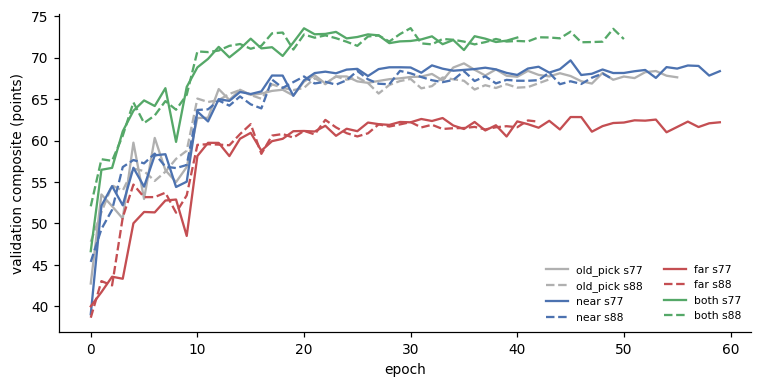

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = {"old_pick": "#b0b0b0", "near": "#4c72b0", "far": "#c44e52", "both": "#55a868"}
for arm in ARMS:
    for seed, ls in zip(SEEDS, ("-", "--")):
        h = pd.read_csv(f"{OUT}/two_{arm}_s{seed}/two_{arm}_s{seed}_history.csv")
        ax.plot(h["epoch"], 100 * h["val_composite"], color=colors[arm], ls=ls, label=f"{arm} s{seed}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation composite (points)"); ax.legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

In [12]:
decision = {"experiment": "two_player", "seeds": SEEDS, "select_metric": SELECT_METRIC, "n_clips": int(len(manifest)),
            "rule": {"min_gain_top1": MIN_GAIN_TOP1, "max_mca_drop": MAX_MCA_DROP},
            "arms_mean": {a: {c: float(mean.loc[a, c]) for c in cols} for a in ARMS}, "selected": selected,
            "subset_accuracy": sub.set_index("arm").to_dict(orient="index")}
os.makedirs(f"{REPO}/configs", exist_ok=True)
with open(f"{REPO}/configs/two_player.json", "w") as f:
    json.dump(decision, f, indent=2)

task = Task.init(project_name=PROJECT, task_name="two_player_summary", task_type=Task.TaskTypes.qc,
                 tags=["two_player", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "seeds": SEEDS, "select_metric": SELECT_METRIC, "split_sha256": split_hash})
log.report_table("validation summary", "val", iteration=0, table_plot=show.reset_index())
log.report_table("rule", "val", iteration=0, table_plot=rule)
log.report_table("subsets", "val", iteration=0, table_plot=sub)
log.report_matplotlib_figure("curves", "val", figure=fig, iteration=0, report_interactive=False)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/two_player.json")
task.close()
print("saved configs/two_player.json")

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=2a51e3a46f904e058c7f01e2dd2ad51a
ClearML results page: https://app.clear.ml/projects/e92c6c54d06a45b3946748122f0d7998/tasks/2a51e3a46f904e058c7f01e2dd2ad51a/output/log
saved configs/two_player.json


## How to read this

- **`near` against `old_pick`.** Both are mostly the same person (about 99% of clips), so a gap comes from the other 1%, from the new pose crops, and from the cleaner selection
  (bystanders excluded). A small gap says the old pick was rarely wrong; it does not say who hits the shot.
- **`far` against `near`.** The far player is about half the height of the near one in the frame, so the pose is less accurate. If `far` is close to `near` on clips where a far player was found, the far player carries
  as much shot information; if it is much lower, either the far skeleton is too noisy or the shot is mostly readable from the near player.
- **`both` against `near`.** The only arm that can use the relation between the two players (who is moving, where the other stands). It also has twice the input; a gain without a subset where it
  shows up (far found) is more likely training noise.
- **Noise.** Two seeds and about 780 validation clips: differences under about 1 point are within noise. A pass is a reason to run the reporting seeds and the other models on the new data, not a result.
- The subsets show where an arm gains or loses; the actor verdicts of notebook 30 (who actually hits the shot) are what turn this into a statement about the wrong player rate.